Check for GPU run

In [4]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no gpu')

True Tesla T4


Install Ultralytics

In [5]:
!pip install -q ultralytics==8.4.216
import ultralytics
print('ultralytics', ultralytics.__version__)

ultralytics 8.4.216


Download prepared dataset

In [6]:
from google.colab import drive
drive.mount('/content/drive')
!wget -q -O /content/f1_subset.zip https://github.com/MiH0per/DeepLearning/releases/download/v1.0/f1_subset.zip
!unzip -q -o /content/f1_subset.zip -d /content/

Mounted at /content/drive


In [7]:
from pathlib import Path
DATA = Path('/content/f1_subset')
(DATA / 'data.yaml').write_text(f"""path: {DATA}
train: train/images
val: valid/images
test: test/images
nc: 4
names: ['Ferrari', 'Mclaren', 'Mercedes', 'Redbull']
""")
for s in ['train', 'valid', 'test']:
    print(s, len(list((DATA / s / 'images').glob('*.jpg'))), len(list((DATA / s / 'labels').glob('*.txt'))))

train 1000 1000
valid 250 250
test 250 250


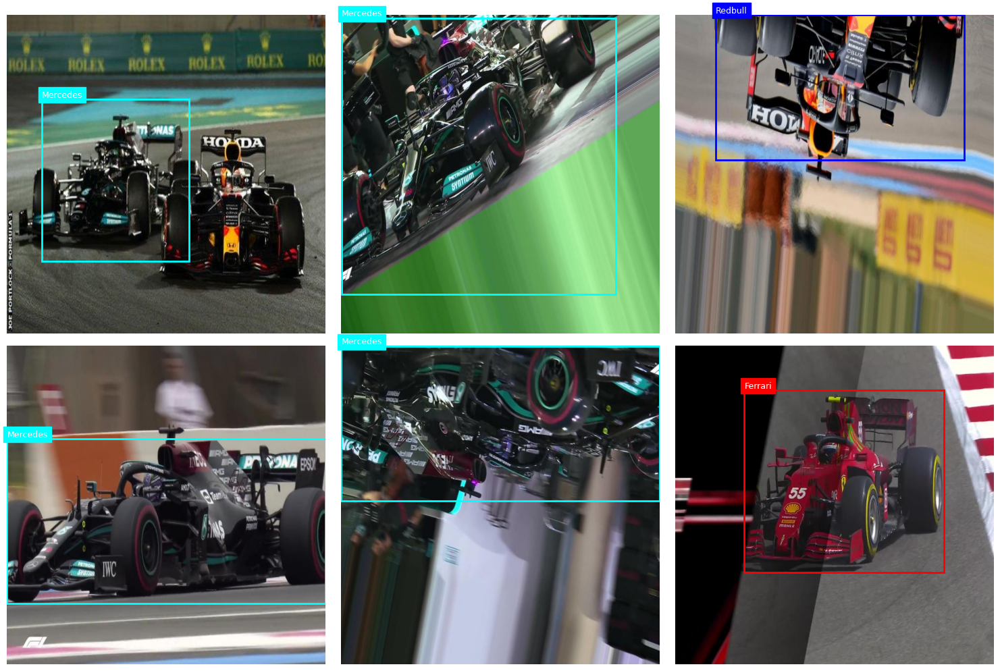

In [8]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

names = ['Ferrari', 'Mclaren', 'Mercedes', 'Redbull']
colors = ['red', 'orange', 'cyan', 'blue']
random.seed(0)
files = random.sample(sorted((DATA / 'train' / 'images').glob('*.jpg')), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.ravel(), files):
    img = Image.open(img_path)
    W, H = img.size
    ax.imshow(img)
    label = DATA / 'train' / 'labels' / (img_path.stem + '.txt')
    for line in label.read_text().splitlines():
        cls, xc, yc, w, h = line.split()
        cls = int(cls)
        xc, yc, w, h = float(xc) * W, float(yc) * H, float(w) * W, float(h) * H
        ax.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h,
                                       fill=False, edgecolor=colors[cls], linewidth=2))
        ax.text(xc - w / 2, yc - h / 2 - 4, names[cls], color='white',
                backgroundcolor=colors[cls], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig('ground_truth_examples.png', dpi=120)
plt.show()

Baseline training

In [9]:
import time
from ultralytics import YOLO

SEED = 42
model = YOLO('yolov8n.pt')
t0 = time.time()
results = model.train(
    data=str(DATA / 'data.yaml'),
    imgsz=640, epochs=30, batch=16,
    optimizer='SGD', lr0=0.01,
    seed=SEED, deterministic=True,
    project='/content/runs', name='baseline', exist_ok=True,
    workers=2, plots=True)
print('baseline training time, min:', round((time.time() - t0) / 60, 1))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/f1_subset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, optim

Save results of baseline run



In [10]:
!mkdir -p /content/drive/MyDrive/f1_runs
!cp -r /content/runs/baseline /content/drive/MyDrive/f1_runs/

Controlled experiment (image size 320)

Hypothesis: a smaller input will train faster, because each image has 4 times fewer pixels. Accuracy will drop, mostly in mAP@0.50:0.95, because boxes become less precise and small or distant cars lose detail. mAP@0.50 may change less, because the baseline is already close to its maximum

In [11]:
model_exp = YOLO('yolov8n.pt')
t0 = time.time()
results_exp = model_exp.train(
    data=str(DATA / 'data.yaml'),
    imgsz=320, epochs=30, batch=16,
    optimizer='SGD', lr0=0.01,
    seed=SEED, deterministic=True,
    project='/content/runs', name='exp_imgsz320', exist_ok=True,
    workers=2, plots=True)
print('experiment training time, min:', round((time.time() - t0) / 60, 1))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/f1_subset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=exp_imgsz320, nbs=64, nms=None, opset=None, optimize=False, o

Save the run

In [12]:
!cp -r /content/runs/exp_imgsz320 /content/drive/MyDrive/f1_runs/

Experiment comparison on the validation set

In [13]:
import pandas as pd

runs = {
    'baseline': ('/content/runs/baseline/weights/best.pt', 640, 8.3),
    'experiment': ('/content/runs/exp_imgsz320/weights/best.pt', 320, 4.8),
}
rows = []
for name, (weights, size, minutes) in runs.items():
    m = YOLO(weights).val(data=str(DATA / 'data.yaml'), split='val', imgsz=size,
                          conf=0.001, iou=0.7, verbose=False, plots=False)
    rows.append({'run': name, 'changed setting': f'imgsz={size}',
                 'precision': round(m.box.mp, 3), 'recall': round(m.box.mr, 3),
                 'mAP@0.50': round(m.box.map50, 3), 'mAP@0.50:0.95': round(m.box.map, 3),
                 'train time, min': minutes})
df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv('/content/drive/MyDrive/f1_runs/comparison_val.csv', index=False)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1295.4±326.1 MB/s, size: 46.7 KB)
val: Scanning /content/f1_subset/valid/labels.cache... 250 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 250/250 61.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 6.4it/s 2.5s
                   all        250        275       0.98      0.954      0.971      0.771
Speed: 1.0ms preprocess, 4.9ms inference, 0.0ms loss, 1.2ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1795.7±584.2 MB/s, size: 41.2 KB)
val: Scanning /content/f1_subset/valid/labels.cache... 250 images, 0 bac

Final evaluation on test set

In [14]:
final = YOLO('/content/runs/baseline/weights/best.pt')
test_m = final.val(data=str(DATA / 'data.yaml'), split='test', imgsz=640,
                   conf=0.001, iou=0.7, project='/content/runs',
                   name='baseline_test', exist_ok=True, plots=True)
print('TEST precision', round(test_m.box.mp, 3), 'recall', round(test_m.box.mr, 3),
      'mAP@0.50', round(test_m.box.map50, 3), 'mAP@0.50:0.95', round(test_m.box.map, 3))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1035.1±368.3 MB/s, size: 41.0 KB)
val: Scanning /content/f1_subset/test/labels... 250 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 250/250 1.6Kit/s 0.2s
val: New cache created: /content/f1_subset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.9it/s 4.1s
                   all        250        277      0.969      0.951      0.969      0.758
               Ferrari         60         61      0.955      0.951      0.958       0.79
               Mclaren         63         64      0.972      0.969      0.976      0.803
              Mercedes         88         92      0.967      0.956      0.978      0.727
               Redbull         57         60      0.982      0.929      0.965     

Test predictions

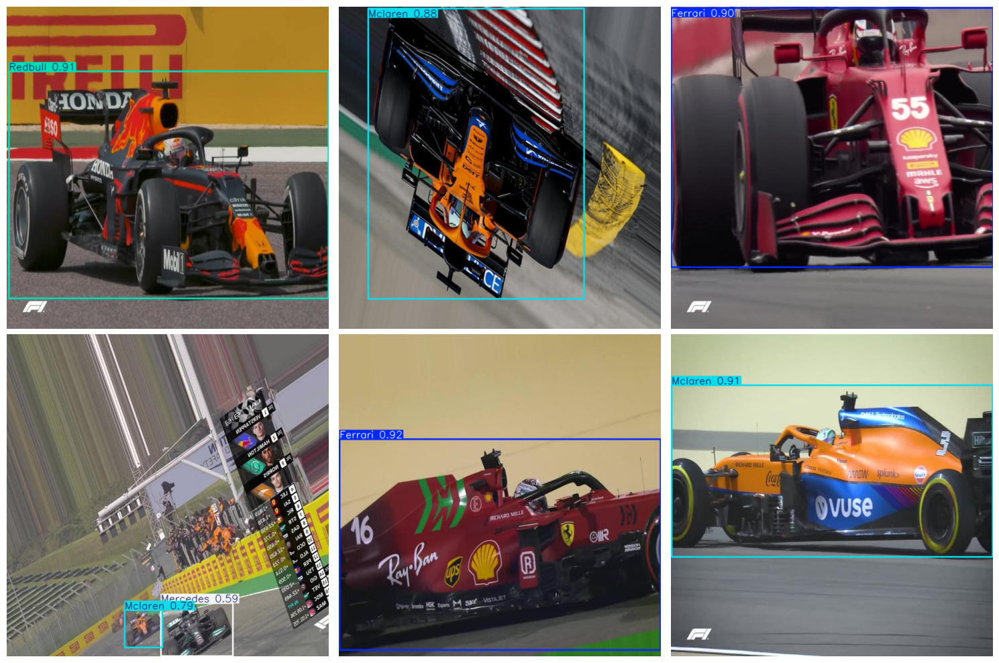

In [15]:
test_imgs = sorted((DATA / 'test' / 'images').glob('*.jpg'))
random.seed(1)
sample = random.sample(test_imgs, 6)
preds = final.predict(sample, imgsz=640, conf=0.25, iou=0.7, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r in zip(axes.ravel(), preds):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/f1_runs/test_predictions.png', dpi=120)
plt.show()

Finding errors

In [16]:
from collections import Counter

def load_gt(img_path):
    W, H = Image.open(img_path).size
    rows = []
    for line in (DATA / 'test' / 'labels' / (img_path.stem + '.txt')).read_text().splitlines():
        c, xc, yc, w, h = map(float, line.split())
        rows.append((int(c), (xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H))
    return rows

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

errors = []
for r in final.predict(test_imgs, imgsz=640, conf=0.25, iou=0.7, verbose=False, stream=True):
    name = Path(r.path).name
    gt = load_gt(Path(r.path))
    pred = [(int(c), *b) for c, b in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
    confs = r.boxes.conf.tolist()
    used = set()
    for g in gt:
        best_j, best_v = None, 0
        for j, p in enumerate(pred):
            v = iou(g[1:], p[1:])
            if v > best_v:
                best_j, best_v = j, v
        if best_v >= 0.5:
            used.add(best_j)
            if pred[best_j][0] != g[0]:
                errors.append(('wrong class', name, f'{names[g[0]]} predicted as {names[pred[best_j][0]]}'))
        elif best_v > 0.1:
            used.add(best_j)
            errors.append(('inaccurate box', name, f'{names[g[0]]}, IoU {best_v:.2f}'))
        else:
            errors.append(('missed', name, names[g[0]]))
    for j, p in enumerate(pred):
        if j not in used:
            errors.append(('false detection', name, f'{names[p[0]]}, conf {confs[j]:.2f}'))

print(Counter(e[0] for e in errors))
for e in errors:
    print(e)

Counter({'false detection': 12, 'wrong class': 3, 'missed': 3, 'inaccurate box': 3})
('false detection', 'Mercedes07021_jpg.rf.308d6343493acffb91466de64a5abe07.jpg', 'Mercedes, conf 0.27')
('false detection', '_0_1573_jpg.rf.aace690439bafb820470de2ecd675465.jpg', 'Mercedes, conf 0.37')
('wrong class', '_0_4120_jpg.rf.7047db44f099747206544aaf13b834f7.jpg', 'Mclaren predicted as Redbull')
('false detection', '_0_421_jpg.rf.1455f1658c61dca176b902f80376184b.jpg', 'Mclaren, conf 0.45')
('false detection', '_0_5200_jpg.rf.f3d83fe3045d883dcb904906a330ebb7.jpg', 'Mclaren, conf 0.52')
('false detection', '_0_5392_jpg.rf.7f98bb0705dd6a42bdbb0cff47a633e8.jpg', 'Mclaren, conf 0.65')
('false detection', '_0_6773_jpg.rf.4f52a7b5c3915f0619426b965e2b87d2.jpg', 'Mercedes, conf 0.67')
('false detection', '_0_6773_jpg.rf.4f52a7b5c3915f0619426b965e2b87d2.jpg', 'Mercedes, conf 0.36')
('wrong class', '_0_7660_jpg.rf.2b1bb2f0267ac174e11a1a34214d4d1d.jpg', 'Mercedes predicted as Mclaren')
('false detection', 

Failed cases

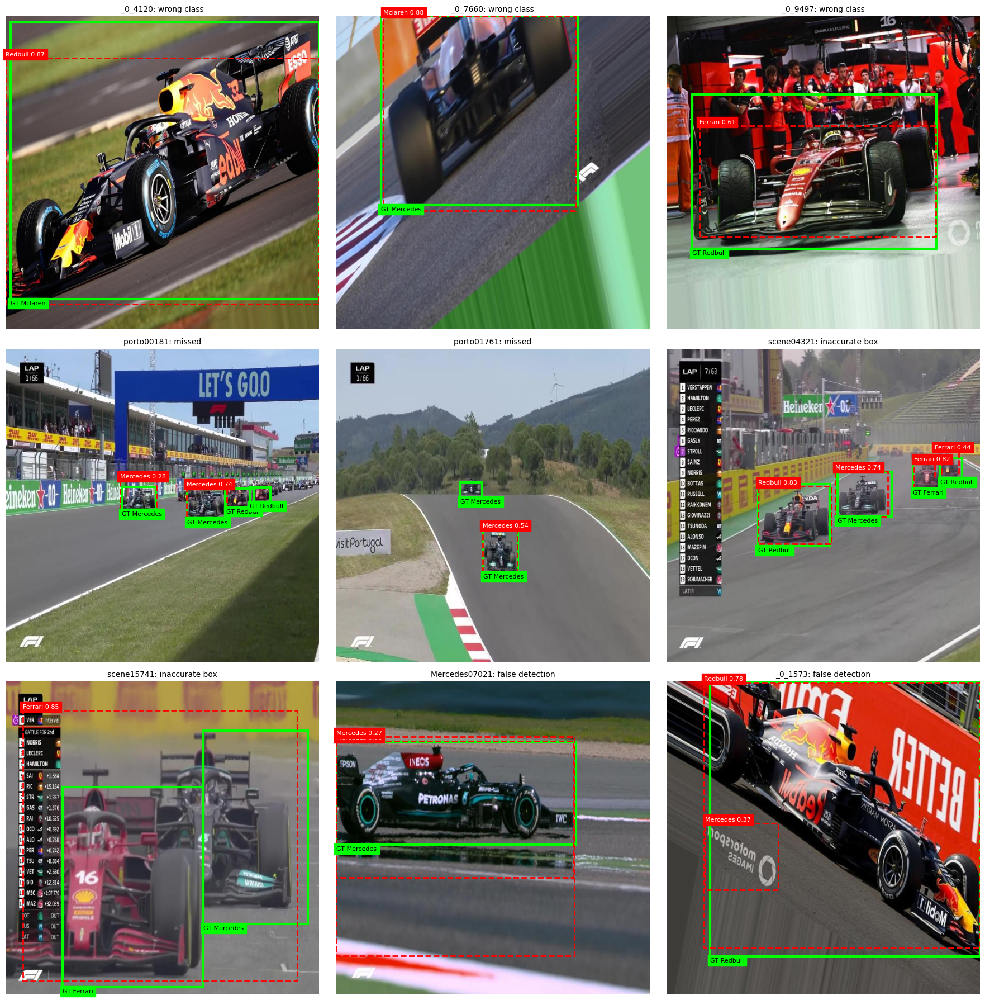

In [17]:
order = ['wrong class', 'missed', 'inaccurate box', 'false detection']
kinds = {}
for kind in order:
    for k, name, info in errors:
        if k == kind:
            kinds.setdefault(name, [])
            if kind not in kinds[name]:
                kinds[name].append(kind)
cand = list(kinds)[:9]
paths = [DATA / 'test' / 'images' / n for n in cand]
res = final.predict(paths, imgsz=640, conf=0.25, iou=0.7, verbose=False)

fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for ax in axes.ravel():
    ax.axis('off')
for ax, p, r in zip(axes.ravel(), paths, res):
    ax.imshow(Image.open(p))
    for c, x1, y1, x2, y2 in load_gt(p):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                       edgecolor='lime', linewidth=3))
        ax.text(x1, y2 + 12, 'GT ' + names[c], color='black', backgroundcolor='lime', fontsize=8)
    for c, cf, (x1, y1, x2, y2) in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                       edgecolor='red', linewidth=2, linestyle='--'))
        ax.text(x1, y1 - 4, f'{names[int(c)]} {cf:.2f}', color='white', backgroundcolor='red', fontsize=8)
    ax.set_title(p.name.split('_jpg')[0] + ': ' + ', '.join(kinds[p.name]), fontsize=10)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/f1_runs/failure_candidates.png', dpi=110)
plt.show()

Predict with the released checkpoint

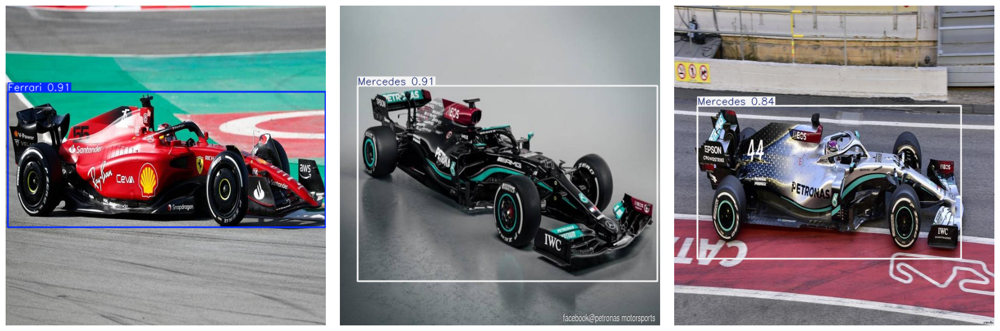

In [18]:
from pathlib import Path
import matplotlib.pyplot as plt
from ultralytics import YOLO

!wget -q -O /content/best_release.pt https://github.com/MiH0per/DeepLearning/releases/download/v1.0/best.pt
release_model = YOLO('/content/best_release.pt')

demo_imgs = sorted(Path('/content/f1_subset/test/images').glob('*.jpg'))[:3]
preds = release_model.predict(demo_imgs, imgsz=640, conf=0.25, iou=0.7, verbose=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, r in zip(axes, preds):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.axis('off')
plt.tight_layout()
plt.show()